# Static 2-D analysis of pipelay initiation and abandonment / recovery — composite line of pipe and steel wire

Static, planar analysis of an S-lay vessel (stinger and pipe data of the Malahy thesis example, Table 5-1: 16-inch pipe, 240 ft of water) handling a **composite line made of pipe and steel wire with different properties**. The line is solved stage by stage while the pipe is gradually lowered.

**Operations (the stage parameter is what changes from stage to stage):**

| Operation | Line | Stage parameter | What lowers the pipe |
|---|---|---|---|
| **Abandonment** | sheave on the vessel – **wire** – pipe end (head) – **pipe** – laid pipeline (seabed end pulled with the seabed lay tension) | wire paid out `L_w` | the head slides down the stinger and into the water as the A&R wire is paid out |
| **Recovery** | same line | `L_w` reduced, same stages in reverse | the head is hauled back up |
| **Initiation** | tensioner on the vessel – **pipe** – pull head – **wire** – seabed anchor | vessel–anchor distance (lay tension held at 40 kips, the pipe length paid out follows) | the pull head descends to the seabed as the vessel moves away from the anchor |

**Method.** The beam-column element of the Malahy thesis (Eq. 2-49/2-51 for the deformation forces, Eq. 2-54 for weight and buoyancy, reduced to the plane: 3 DOF per node X, Y, β) is used for *both* materials, each element carrying its own `EA`, `EI`, weight in air and submerged weight. The static equilibrium is solved by Newton–Raphson on the residual force vector (Eq. 2-4, §3.1) with a central-difference tangent; the stages are reached by continuation in the stage parameter.

**What is different from the earlier pipelay notebook (and why):**
1. **Rollers act on the pipe wherever it lies, not on tied nodes.** The pipe end / head travels tens of metres along the stinger, so a node can no longer be pinned to "its" roller. Each roller is a smoothed unilateral spring along the normal of the support line; the contact point is found where the element's cubic-Hermite centreline crosses the roller's line, and the reaction is distributed to the element DOFs by the Hermite weights. The wire rides on the same rollers (wire radius ignored).
2. **Composite chain with a pinned head.** The pipe end and the wire eye share position but have their own rotation, so no moment is transmitted between pipe and wire.
3. **Tension / pay-out control.** In abandonment the pipeline is pulled at the seabed end by a prescribed horizontal force (the seabed lay tension); in initiation the lay tension at the tensioner is prescribed and the pipe length paid out is an extra unknown of the Newton iteration (all pipe elements are scaled by λ).

**Assumed values (not in the thesis — change them at the top of the relevant cells):** steel wire rope Ø76 mm, 20.8 kg/m in air, `EA = 3.2·10⁸ N`, `EI = 5·10⁴ N·m²` (a small non-zero value keeps a slack wire well conditioned), pull-head weight 6 kN, seabed lay tension 100 kN (the steady-lay value from the earlier notebook), wire length 55 m in the initiation, deck 24 ft above the water, frictionless seabed (soil spring `2·10⁶ N/m`), roller stiffness `2·10⁷ N/m`, stinger modelled as a rigid roller bed.

**Limits to keep in mind.** Static only (no vessel motion, no dynamics); frictionless rollers and seabed, so recovery follows the same equilibrium path as abandonment (checked below); friction or a change of line weight would make it differ. The thesis does not treat these operations, so there are no published numbers to compare with here; the checks are convergence of every stage, reversibility of the A&R path, and agreement of stage 0 with the steady-lay solution.

SI units (1 ft = 0.3048 m, 1 kip = 4448.2 N).

In [1]:
import numpy as np, scipy.linalg, scipy.special
from scipy.optimize import brentq
import matplotlib.pyplot as plt

FT, LBF, KIP = 0.3048, 4.4482216, 4448.2216
G_ACC, RHO_W = 9.81, 1025.0

# ------------------------------------------------------------------ line properties
class Prop:
    def __init__(s, name, EA, EI, w_air, w_sub, D, E=None, D_steel=None):
        s.name, s.EA, s.EI, s.w_air, s.w_sub, s.D = name, EA, EI, w_air, w_sub, D
        s.D_steel = D_steel if D_steel else D
        s.E = E

def make_pipe(D_steel=16*0.0254, t=0.5*0.0254, t_coat=2*0.0254, E=207e9, w_air=191.6*LBF/FT, w_sub=52.0*LBF/FT):
    d_in = D_steel - 2*t
    return Prop('pipe', E*np.pi/4*(D_steel**2-d_in**2), E*np.pi/64*(D_steel**4-d_in**4), w_air, w_sub, D_steel+2*t_coat, E, D_steel)

def make_wire(d=0.076, EA=3.2e8, EI=5.0e4, m_air=20.8, steel_density=6000.0):
    w_air = m_air*G_ACC; w_sub = w_air*(1-RHO_W/steel_density)
    return Prop('wire', EA, EI, w_air, w_sub, d, None, d)

# ------------------------------------------------------------------ planar Malahy beam-column element (Eq. 2-51, 2-54 reduced to the plane)
def wrap(a): return (a+np.pi) % (2*np.pi) - np.pi

def elem_force(p, L0, pr, y_w):
    """End forces [Fx1,Fy1,M1,Fx2,Fy2,M2] on the two nodes of one element (forces exerted by the element + equivalent weight loads)."""
    xa, ya, ba, xb, yb, bb = p
    dx, dy = xb-xa, yb-ya; L = np.hypot(dx, dy); g = np.arctan2(dy, dx)
    th1, th2 = wrap(ba-g), wrap(bb-g)                         # end rotations relative to the chord
    bow = ((2*th1-th2)*th1 + 2*th2**2)/30.0                   # bowing shortening (beam-column coupling)
    T = pr.EA*(L/L0 + bow - 1.0); TL = T*L0
    f1, f7 = T, -T
    f6  = -2*pr.EI/L0*(2*th1+th2) - TL*(4*th1-th2)/30
    f12 = -2*pr.EI/L0*(th1+2*th2) - TL*(4*th2-th1)/30
    f2 = (f6+f12)/L; f8 = -f2
    h1, h2 = ya-y_w, yb-y_w                                   # submerged fraction
    if h1 <= 0 and h2 <= 0: sub = 1.0
    elif h1 > 0 and h2 > 0: sub = 0.0
    else: sub = -min(h1, h2)/abs(h1-h2)
    w = (1-sub)*pr.w_air + sub*pr.w_sub
    c, s = np.cos(g), np.sin(g)
    Qx, Qy = -w*s, -w*c                                       # gravity in the element axes
    dth = th1-th2
    f1 += Qx*L0/2 - Qy*L0*dth/12;  f2 += Qy*L0/2 + Qx*L0*dth/12;  f6 += Qy*L0*L/12
    f7 += Qx*L0/2 + Qy*L0*dth/12;  f8 += Qy*L0/2 - Qx*L0*dth/12;  f12 += -Qy*L0*L/12
    return np.array([c*f1-s*f2, s*f1+c*f2, f6, c*f7-s*f8, s*f7+c*f8, f12])

def elem_tension(p, L0, pr):
    xa, ya, ba, xb, yb, bb = p
    dx, dy = xb-xa, yb-ya; L = np.hypot(dx, dy); g = np.arctan2(dy, dx)
    th1, th2 = wrap(ba-g), wrap(bb-g)
    return pr.EA*(L/L0 + ((2*th1-th2)*th1 + 2*th2**2)/30.0 - 1.0)


## Line properties: pipe versus steel wire

In [2]:
pipe, wire = make_pipe(), make_wire()
print(f"{'':28s}{'pipe':>14s}{'steel wire':>14s}")
for lbl, a, b, f in [('outer diameter (m)', pipe.D, wire.D, '{:.3f}'), ('EA (N)', pipe.EA, wire.EA, '{:.3e}'), ('EI (N m^2)', pipe.EI, wire.EI, '{:.3e}'),
                     ('weight in air (N/m)', pipe.w_air, wire.w_air, '{:.0f}'), ('submerged weight (N/m)', pipe.w_sub, wire.w_sub, '{:.0f}')]:
    print(f"{lbl:28s}{f.format(a):>14s}{f.format(b):>14s}")
print(f"{'EA ratio pipe/wire':28s}{pipe.EA/wire.EA:14.1f}\n{'EI ratio pipe/wire':28s}{pipe.EI/wire.EI:14.0f}")

                                      pipe    steel wire
outer diameter (m)                   0.508         0.076
EA (N)                           3.252e+09     3.200e+08
EI (N m^2)                       6.306e+07     5.000e+04
weight in air (N/m)                   2796           204
submerged weight (N/m)                 759           169
EA ratio pipe/wire                    10.2
EI ratio pipe/wire                    1261


## Contact, line model and Newton–Raphson solver

In [3]:
# ------------------------------------------------------------------ cubic Hermite centreline of an element (global form of the thesis' shape functions)
def hermite_pt(pa, ba, pb, bb, xi):
    Lc = np.hypot(*(pb-pa)); ta = np.array([np.cos(ba), np.sin(ba)]); tb = np.array([np.cos(bb), np.sin(bb)])
    H = np.array([2*xi**3-3*xi**2+1, xi**3-2*xi**2+xi, -2*xi**3+3*xi**2, xi**3-xi**2])
    return H[0]*pa + H[1]*Lc*ta + H[2]*pb + H[3]*Lc*tb, H, Lc

class Support:
    """Roller of the laybarge / stinger: unilateral spring along the normal of the support line, acting on whatever part of the line (pipe or wire) crosses it."""
    def __init__(s, P, phi):
        s.P = np.array(P, float); s.t = np.array([np.cos(phi), -np.sin(phi)]); s.n = np.array([np.sin(phi), np.cos(phi)])

class Line:
    """Chain of nodes (x, y, beta) joined by beam-column elements of different properties.
       tie: {node_b: node_a} makes node_b share x,y with node_a but keep its own rotation (pinned joint: pipe end / wire eye)."""
    def __init__(s, pos, elems, L0, tie, fixed, supports, y_water, y_bed, K_roll=2e7, K_soil=2e6, eps_roll=1e-3, eps_soil=2e-3, gap_window=1.5):
        s.pos0 = np.array(pos, float); s.N = len(pos); s.elems = elems; s.L0 = np.array(L0, float); s.tie = tie
        s.supports = supports; s.y_water, s.y_bed = y_water, y_bed
        s.K_roll, s.K_soil, s.eps_roll, s.eps_soil, s.gap_window = K_roll, K_soil, eps_roll, eps_soil, gap_window
        s.dm = np.zeros((s.N, 3), int); n = 0
        for i in range(s.N):
            if i in tie: s.dm[i, :2] = s.dm[tie[i], :2]; s.dm[i, 2] = n; n += 1
            else: s.dm[i] = [n, n+1, n+2]; n += 3
        s.nq = n
        s.eidx = [np.r_[s.dm[i], s.dm[j]] for (i, j, _) in elems]
        s.fixed_dofs = set(); 
        for i in fixed: s.fixed_dofs |= {s.dm[i, 0], s.dm[i, 1]}
        s.node_force = {}                    # node -> (Fx, Fy) constant nodal loads (head weight, far-end pull)
        s.scale_elems = []                   # indices of elements whose L0 is scaled by the pay-out unknown
        s.lam = 1.0; s.tension_control = None   # (element, target tension)
        s.set_free()
    def set_free(s):
        s.free = np.array([k for k in range(s.nq) if k not in s.fixed_dofs])
    def q0(s):
        q = np.zeros(s.nq)
        for i in range(s.N): q[s.dm[i]] = s.pos0[i]
        return q
    def L0e(s, e): return s.L0[e]*(s.lam if e in s.scale_elems else 1.0)
    # ---- contact search: where does the chain cross each support line, and what is the gap there?
    def find_contacts(s, q):
        X = np.array([q[s.dm[i, :2]] for i in range(s.N)]); out = []
        ea = np.array([e[0] for e in s.elems]); eb = np.array([e[1] for e in s.elems])
        for sp in s.supports:
            u = (X-sp.P)@sp.t; ua, ub = u[ea], u[eb]
            cand = np.flatnonzero((ua <= 0) & (ub > 0)); best = None
            for e in cand:
                xi, g = s.solve_xi(q, e, sp)
                if best is None or abs(g) < abs(best[2]): best = (e, xi, g)
            out.append(best)
        return out
    def solve_xi(s, q, e, sp):
        i, j, _ = s.elems[e]; pa, pb = q[s.dm[i, :2]], q[s.dm[j, :2]]; ba, bb = q[s.dm[i, 2]], q[s.dm[j, 2]]
        f = lambda xi: (hermite_pt(pa, ba, pb, bb, xi)[0]-sp.P)@sp.t
        lo, hi = 0.0, 1.0
        flo, fhi = f(lo), f(hi)
        if flo*fhi > 0: xi = 0.0 if abs(flo) < abs(fhi) else 1.0
        else:
            for _ in range(40):
                mid = 0.5*(lo+hi)
                if f(mid) > 0: hi = mid
                else: lo = mid
            xi = 0.5*(lo+hi)
        return xi, (hermite_pt(pa, ba, pb, bb, xi)[0]-sp.P)@sp.n
    def contact_vec(s, q, e, xi, sp):
        """Generalised forces on the 6 DOFs of element e from the roller reaction at parameter xi (Hermite virtual work)."""
        i, j, _ = s.elems[e]; pa, pb = q[s.dm[i, :2]], q[s.dm[j, :2]]; ba, bb = q[s.dm[i, 2]], q[s.dm[j, 2]]
        pt, H, Lc = hermite_pt(pa, ba, pb, bb, xi); g = (pt-sp.P)@sp.n
        if abs(g) > s.gap_window: return np.zeros(6), 0.0, g
        Rn = s.K_roll*s.eps_roll*np.logaddexp(0.0, -g/s.eps_roll); F = Rn*sp.n
        dta = np.array([-np.sin(ba), np.cos(ba)]); dtb = np.array([-np.sin(bb), np.cos(bb)])
        return np.r_[H[0]*F, H[1]*Lc*(F@dta), H[2]*F, H[3]*Lc*(F@dtb)], Rn, g
    # ---- residual
    def residual(s, q, contacts=None):
        R = np.zeros(s.nq)
        for e, (i, j, pr) in enumerate(s.elems):
            R[s.eidx[e]] += elem_force(q[s.eidx[e]], s.L0e(e), pr, s.y_water)
        done = set()
        for i in range(s.N):                                  # seabed (once per physical point)
            if i in s.tie: continue
            y = q[s.dm[i, 1]]; R[s.dm[i, 1]] += s.K_soil*s.eps_soil*np.logaddexp(0.0, (s.y_bed-y)/s.eps_soil)
        for i, (fx, fy) in s.node_force.items(): R[s.dm[i, 0]] += fx; R[s.dm[i, 1]] += fy
        if contacts is None: contacts = s.find_contacts(q)
        for sp, c in zip(s.supports, contacts):
            if c is None: continue
            v, _, _ = s.contact_vec(q, c[0], c[1], sp); R[s.eidx[c[0]]] += v
        return R
    # ---- tangent: element-wise central differences
    def jacobian(s, q, contacts):
        J = np.zeros((s.nq, s.nq)); hs = np.array([1e-6, 1e-6, 1e-7]*2)
        for e, (i, j, pr) in enumerate(s.elems):
            idx = s.eidx[e]; p0 = q[idx]; L0 = s.L0e(e); Je = np.zeros((6, 6))
            for k in range(6):
                pp, pm = p0.copy(), p0.copy(); pp[k] += hs[k]; pm[k] -= hs[k]
                Je[:, k] = (elem_force(pp, L0, pr, s.y_water)-elem_force(pm, L0, pr, s.y_water))/(2*hs[k])
            np.add.at(J, (idx[:, None], idx[None, :]), Je)
        for i in range(s.N):
            if i in s.tie: continue
            y = q[s.dm[i, 1]]; J[s.dm[i, 1], s.dm[i, 1]] += -s.K_soil*scipy.special.expit((s.y_bed-y)/s.eps_soil)
        for sp, c in zip(s.supports, contacts):
            if c is None: continue
            e, xi0 = c[0], c[1]; idx = s.eidx[e]; Jc = np.zeros((6, 6))
            for k in range(6):
                qp, qm = q.copy(), q.copy(); h = hs[k]; qp[idx[k]] += h; qm[idx[k]] -= h
                xp, _ = s.solve_xi(qp, e, sp); xm, _ = s.solve_xi(qm, e, sp)
                Jc[:, k] = (s.contact_vec(qp, e, xp, sp)[0]-s.contact_vec(qm, e, xm, sp)[0])/(2*h)
            np.add.at(J, (idx[:, None], idx[None, :]), Jc)
        return J
    def tensions(s, q):
        return np.array([elem_tension(q[s.eidx[e]], s.L0e(e), pr) for e, (i, j, pr) in enumerate(s.elems)])
    # ---- Newton-Raphson (Section 3.1), optionally with the pay-out unknown (tension control at element te)
    def solve(s, q, tol=1.0, maxit=40, verbose=False):
        q = q.copy(); fr = s.free; tc = s.tension_control
        def full(q, lam):
            s.lam = lam; c = s.find_contacts(q); R = s.residual(q, c)[fr]
            if tc is not None:
                te, Tt = tc; R = np.r_[R, (s.tensions(q)[te]-Tt)*1.0]
            return R, c
        lam = s.lam; R, c = full(q, lam); r0 = np.linalg.norm(R)
        for it in range(maxit):
            J = s.jacobian(q, c)[np.ix_(fr, fr)]
            if tc is not None:
                te, Tt = tc
                dRdl = np.zeros(len(fr)); h = 1e-6
                s.lam = lam+h; Rp = s.residual(q, c)[fr]; s.lam = lam-h; Rm = s.residual(q, c)[fr]; dRdl = (Rp-Rm)/(2*h); s.lam = lam
                g_row = np.zeros(len(fr)); idx = s.eidx[te]; pr = s.elems[te][2]; hs = np.array([1e-6, 1e-6, 1e-7]*2)
                pos = {d: k for k, d in enumerate(fr)}
                for k in range(6):
                    pp, pm = q[idx].copy(), q[idx].copy(); pp[k] += hs[k]; pm[k] -= hs[k]
                    gk = (elem_tension(pp, s.L0e(te), pr)-elem_tension(pm, s.L0e(te), pr))/(2*hs[k])
                    if idx[k] in pos: g_row[pos[idx[k]]] += gk
                s.lam = lam+h; Tp_ = s.tensions(q)[te]; s.lam = lam-h; Tm_ = s.tensions(q)[te]; s.lam = lam
                Jf = np.zeros((len(fr)+1, len(fr)+1)); Jf[:-1, :-1] = J; Jf[:-1, -1] = dRdl; Jf[-1, :-1] = g_row; Jf[-1, -1] = (Tp_-Tm_)/(2*h)
                J = Jf
            try: dz = np.linalg.solve(J, -R)
            except np.linalg.LinAlgError: return q, False, it
            a = 1.0
            while True:
                qn = q.copy(); qn[fr] += a*dz[:len(fr)]; ln = lam + (a*dz[-1] if tc is not None else 0.0)
                Rn, cn = full(qn, ln); rn = np.linalg.norm(Rn)
                if (np.isfinite(rn) and rn < (1-1e-4*a)*r0) or a < 1e-3: break
                a *= 0.5
            q, lam, R, c, r0 = qn, ln, Rn, cn, rn
            if verbose: print(it, r0, a, lam)
            if r0 < tol: s.lam = lam; return q, True, it+1
        s.lam = lam
        return q, False, maxit


## Vessel geometry and scenario builders

Same vessel as Table 5-1: laybarge arc R = 750 ft (160 ft long), stinger arc R = 700 ft (240 ft long), 12 roller supports (40 ft spacing on the barge, 30 ft on the stinger).

In [4]:
# ------------------------------------------------------------------ vessel geometry (Table 5-1): barge arc R = 750 ft (160 ft), stinger arc R = 700 ft (240 ft)
RB, RS, S_HITCH, S_TIP = 750*FT, 700*FT, 160*FT, 400*FT
def arc(s):
    s = np.atleast_1d(s).astype(float); out = []
    for sv in s:
        if sv <= S_HITCH: ph = sv/RB; out.append((RB*np.sin(ph), -RB*(1-np.cos(ph)), ph))
        else:
            ph0 = S_HITCH/RB; x0, y0 = RB*np.sin(ph0), -RB*(1-np.cos(ph0)); ph = ph0+(sv-S_HITCH)/RS
            out.append((x0+RS*(np.sin(ph)-np.sin(ph0)), y0-RS*(np.cos(ph0)-np.cos(ph)), ph))
    return np.array(out)

def make_supports(s_list):
    return [Support(p[:2], p[2]) for p in arc(s_list)]

SUPPORT_S = np.r_[np.array([40, 80, 120, 160])*FT, np.array([190, 220, 250, 280, 310, 340, 370, 400])*FT]

# ------------------------------------------------------------------ scenario helpers
def free_span_nodes(x_t, y_t, ang, y_bed, ds):
    """Initial guess after the stinger tip: tangent angle falls linearly from `ang` (downward) to 0 over the length that drops to the seabed."""
    H = y_t - y_bed
    drop = lambda Ls: np.trapz(np.sin(ang*(1-np.linspace(0, Ls, 400)/Ls)), np.linspace(0, Ls, 400))
    Ls = brentq(lambda L: drop(L)-H, 10, 5000); m = max(int(round(Ls/ds)), 4); d = Ls/m
    x, y, pts = x_t, y_t, []
    for k in range(m):
        am = ang*(1-(k+0.5)/m); x += d*np.cos(am); y -= d*np.sin(am); pts.append((x, y, -ang*(1-(k+1)/m)))
    return pts

def stress_pipe(line, q, elems):
    """Bending stress (Pa) in the given pipe elements from the node-tangent change per element length: sigma = E (D/2) kappa."""
    out = []
    for e in elems:
        i, j, pr = line.elems[e]; xa, xb = q[line.dm[i, :2]], q[line.dm[j, :2]]
        kappa = (q[line.dm[j, 2]]-q[line.dm[i, 2]])/np.hypot(*(xb-xa)); out.append(pr.E*pr.D_steel/2*kappa)
    return np.array(out)

def roller_reactions(line, q):
    """Normal reaction (N) at every support (0 where nothing touches it), and the support that carries it."""
    cs = line.find_contacts(q); out = []
    for sp, c in zip(line.supports, cs):
        out.append(0.0 if c is None else line.contact_vec(q, c[0], c[1], sp)[1])
    return np.array(out)

def centreline(line, q, elems, n=10):
    """Sampled cubic-Hermite centreline of a group of elements (x, y) for plotting."""
    pts = []
    for e in elems:
        i, j, _ = line.elems[e]; pa, pb = q[line.dm[i, :2]], q[line.dm[j, :2]]; ba, bb = q[line.dm[i, 2]], q[line.dm[j, 2]]
        for xi in np.linspace(0, 1, n, endpoint=(e == elems[-1])): pts.append(hermite_pt(pa, ba, pb, bb, xi)[0])
    return np.array(pts)

def march(line, q, setter, p_from, p_to, dp_max, tol=1.0, verbose=False):
    """Continuation in a stage parameter: setter(line, q, p) -> q applies the parameter; the step is halved when Newton fails."""
    p, dp = p_from, dp_max*np.sign(p_to-p_from)
    while abs(p_to-p) > 1e-12:
        step = dp if abs(p_to-p) > abs(dp) else p_to-p
        qn = setter(line, q.copy(), p+step); qs, ok, it = line.solve(qn, tol=tol, maxit=25)
        if ok: q, p = qs, p+step; dp = dp*1.5 if abs(dp) < dp_max else dp
        else:
            dp *= 0.5
            if abs(dp) < 1e-6: raise RuntimeError(f"no convergence near parameter {p:.4f}")
        if verbose: print(f"p={p:.3f} ok={ok} step={step:.3f}")
    return q

def build_ar(pipe, wire, s_head0=14.0, n_w=26, ds=12.0, seabed_len=220.0, H_far=100e3, W_head=6e3,
             deck_above_water=24*FT, depth=240*FT, Lw0=None):
    """Abandonment / recovery: [sheave on the vessel] -wire- [head] -pipe- [far end on the seabed, pulled by H_far]."""
    y_water = -deck_above_water; y_bed = y_water - depth
    nodes = []; elems = []
    sw = np.linspace(0, s_head0, n_w+1)
    for p in arc(sw): nodes.append((p[0], p[1], -p[2]))
    ip0 = len(nodes)                                          # pipe end (head), tied to the last wire node
    n_arc = int(np.ceil((S_TIP-s_head0)/ds)); sp = s_head0 + (S_TIP-s_head0)*np.arange(0, n_arc+1)/n_arc
    for p in arc(sp): nodes.append((p[0], p[1], -p[2]))
    xt, yt, bt = nodes[-1]
    nodes += free_span_nodes(xt, yt, -bt, y_bed, ds)
    x, y, _ = nodes[-1]
    for k in range(int(seabed_len/ds)): x += ds; nodes.append((x, y_bed, 0.0))
    nodes = np.array(nodes); N = len(nodes)
    for i in range(n_w): elems.append((i, i+1, wire))
    for i in range(ip0, N-1): elems.append((i, i+1, pipe))
    tie = {ip0: n_w}
    L0 = []
    for (i, j, pr) in elems:
        c = np.hypot(*(nodes[j, :2]-nodes[i, :2])); b = [nodes[i, 2]-np.arctan2(*(nodes[j, 1::-1]-nodes[i, 1::-1])), nodes[j, 2]-np.arctan2(*(nodes[j, 1::-1]-nodes[i, 1::-1]))]
        L0.append(c*(1+((2*b[0]-b[1])*b[0]+2*b[1]**2)/30.0))
    line = Line(nodes, elems, L0, tie, [0], make_supports(SUPPORT_S), y_water, y_bed)
    line.node_force = {ip0: (0.0, -W_head), N-1: (H_far, 0.0)}
    line.wire_elems = list(range(n_w)); line.pipe_elems = list(range(n_w, len(elems))); line.head = ip0; line.far = N-1; line.n_w = n_w
    line.L_wire0 = sum(L0[e] for e in line.wire_elems)
    return line

def set_wire_length(line, q, Lw):
    for e in line.wire_elems: line.L0[e] = Lw/line.n_w
    return q

def build_init(pipe, wire, n_w=12, L_w=55.0, ds=12.0, head_beyond=40.0, W_head=6e3, deck_above_water=24*FT, depth=240*FT, T_t=40*KIP):
    """Initiation: [tensioner on the barge] -pipe- [pull head] -wire- [seabed anchor].
       Stage parameters: anchor position (vessel-anchor distance) and the pipe length paid out (line.lam scales all pipe elements)."""
    y_water = -deck_above_water; y_bed = y_water - depth
    n_arc = int(np.ceil(S_TIP/ds)); sp = S_TIP*np.arange(0, n_arc+1)/n_arc
    nodes = [(p[0], p[1], -p[2]) for p in arc(sp)]
    xt, yt, bt = nodes[-1]
    nodes += free_span_nodes(xt, yt, -bt, y_bed, ds)
    x, y, _ = nodes[-1]
    for k in range(int(head_beyond/ds)): x += ds; nodes.append((x, y_bed, 0.0))
    ip_end = len(nodes)-1                                      # pull head = pipe end
    for k in range(n_w): x += L_w/n_w; nodes.append((x, y_bed, 0.0))
    nodes = np.array(nodes); N = len(nodes)
    nodes[ip_end+1] = nodes[ip_end]                            # first wire node: same position as the head, own rotation (pinned eye)
    tie = {ip_end+1: ip_end}
    elems = [(i, i+1, pipe) for i in range(ip_end)] + [(i, i+1, wire) for i in range(ip_end+1, N-1)]
    L0 = []
    for (i, j, pr) in elems:
        c = np.hypot(*(nodes[j, :2]-nodes[i, :2])); g = np.arctan2(nodes[j, 1]-nodes[i, 1], nodes[j, 0]-nodes[i, 0]); b_ = [nodes[i, 2]-g, nodes[j, 2]-g]
        L0.append(c*(1+((2*b_[0]-b_[1])*b_[0]+2*b_[1]**2)/30.0))
    line = Line(nodes, elems, L0, tie, [0, N-1], make_supports(SUPPORT_S), y_water, y_bed)
    line.pipe_elems = list(range(ip_end)); line.wire_elems = list(range(ip_end, len(elems))); line.head = ip_end; line.anchor = N-1; line.n_w = n_w
    line.scale_elems = list(line.pipe_elems); line.node_force = {ip_end: (0.0, -W_head)}; line.T_t = T_t
    for e in line.wire_elems: line.L0[e] = L_w/len(line.wire_elems)
    return line

def set_pipe_length(line, q, lam):
    line.lam = lam; return q

def set_anchor_x(line, q, xA):
    q[line.dm[line.anchor, 0]] = xA; return q


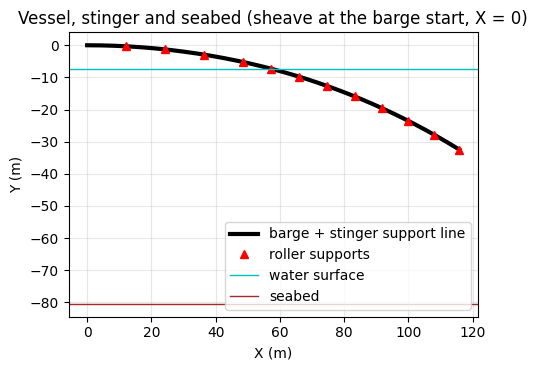

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 3.8))
ss = np.linspace(0, S_TIP, 200); P = arc(ss)
ax.plot(P[:, 0], P[:, 1], 'k-', lw=3, label='barge + stinger support line'); ax.plot([s.P[0] for s in make_supports(SUPPORT_S)], [s.P[1] for s in make_supports(SUPPORT_S)], 'r^', label='roller supports')
ax.axhline(-24*FT, color='c', lw=1, label='water surface'); ax.axhline(-24*FT-240*FT, color='brown', lw=1, label='seabed')
ax.set_aspect('equal'); ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.legend(loc='lower right'); ax.grid(alpha=.3); ax.set_title('Vessel, stinger and seabed (sheave at the barge start, X = 0)')
plt.tight_layout(); plt.show()

## Part A — Abandonment and recovery

Line: sheave (fixed on the vessel at the start of the barge) – A&R wire – head – pipe – laid pipeline, the seabed end of which is pulled by the seabed lay tension. **Stage 0** has the head 14 m from the sheave on the barge deck, the wire carrying the full pipe tension. The wire is then paid out in stages: the head slides over the rollers, leaves the stinger tip and sinks until it lands on the seabed.

In [6]:
import time
def snapshot(line, q, tag):
    T = line.tensions(q); hx, hy = q[line.dm[line.head, :2]]
    sig = np.abs(stress_pipe(line, q, line.pipe_elems)).max()/1e6
    return dict(tag=tag, q=q.copy(), head=(hx, hy), clear=hy-line.y_bed, T=T, sig=sig, rr=roller_reactions(line, q), lam=line.lam,
                res=np.linalg.norm(line.residual(q)[line.free]))

ar = build_ar(pipe, wire)
q, ok, nit = ar.solve(ar.q0()); print(f"stage 0 converged: {ok} ({nit} iterations); {ar.N} nodes, {ar.nq} DOF")
stages_Lw = [14, 40, 80, 120, 160, 200, 240, 280, 300]           # wire paid out (m) = stage parameter
ABAN = {}; t0 = time.time(); Lw = stages_Lw[0]; set_wire_length(ar, q, Lw); q, ok, _ = ar.solve(q); ABAN[Lw] = snapshot(ar, q, 'abandonment')
for tgt in stages_Lw[1:]:
    q = march(ar, q, set_wire_length, Lw, tgt, 3.0); Lw = tgt; ABAN[Lw] = snapshot(ar, q, 'abandonment')
print(f"abandonment: {len(stages_Lw)} stages in {time.time()-t0:.0f} s; worst residual {max(v['res'] for v in ABAN.values()):.2e} N")

stage 0 converged: True (19 iterations); 70 nodes, 208 DOF
abandonment: 9 stages in 99 s; worst residual 6.05e-01 N


In [7]:
# Recovery = the same stages in reverse (continuation from the final abandonment state)
REC = {}; t0 = time.time(); qr = q.copy(); Lr = stages_Lw[-1]; REC[Lr] = snapshot(ar, qr, 'recovery')
for tgt in stages_Lw[::-1][1:]:
    qr = march(ar, qr, set_wire_length, Lr, tgt, 3.0); Lr = tgt; REC[Lr] = snapshot(ar, qr, 'recovery')
dq = max(np.abs(REC[L]['q']-ABAN[L]['q']).max() for L in stages_Lw)
print(f"recovery: {time.time()-t0:.0f} s; largest difference between recovery and abandonment states: {dq:.2e} m / rad  (frictionless: path independent)")

recovery: 93 s; largest difference between recovery and abandonment states: 2.49e-06 m / rad  (frictionless: path independent)


In [8]:
def table(D, keys, label):
    print(label); print(f"{'L_w':>6s}{'head X':>9s}{'head Y':>9s}{'clear':>8s}{'T wire@sheave':>15s}{'T wire@head':>13s}{'T pipe@head':>13s}{'max bend.':>11s}{'max roller':>11s}{'far end X':>10s}")
    print(f"{'(m)':>6s}{'(m)':>9s}{'(m)':>9s}{'(m)':>8s}{'(kN)':>15s}{'(kN)':>13s}{'(kN)':>13s}{'(MPa)':>11s}{'(kN)':>11s}{'(m)':>10s}")
    for L in keys:
        d = D[L]; T = d['T']; qq = d['q']
        print(f"{L:6.0f}{d['head'][0]:9.1f}{d['head'][1]:9.1f}{d['clear']:8.1f}{T[0]/1e3:15.1f}{T[ar.wire_elems[-1]]/1e3:13.1f}{T[ar.pipe_elems[0]]/1e3:13.1f}{d['sig']:11.1f}{d['rr'].max()/1e3:11.1f}{qq[ar.dm[ar.far, 0]]:10.0f}")
table(ABAN, stages_Lw, 'ABANDONMENT (lowering)'); print(); table(REC, stages_Lw[::-1], 'RECOVERY (raising)')
print(f"\nStage-0 check: wire tension {ABAN[14]['T'][0]/1e3:.0f} kN carries the pipe tension; the steady-lay solution of the earlier notebook has 178 kN at the tensioner.")
print(f"Seabed end: pipe tension at the far end {ABAN[300]['T'][ar.pipe_elems[-1]]/1e3:.0f} kN (applied lay tension 100 kN).")

ABANDONMENT (lowering)
   L_w   head X   head Y   clear  T wire@sheave  T wire@head  T pipe@head  max bend. max roller far end X
   (m)      (m)      (m)     (m)           (kN)         (kN)         (kN)      (MPa)       (kN)       (m)
    14     14.0     -0.4    80.1          175.9        175.8        173.2      252.1       71.7       498
    40     39.8     -3.4    77.1          168.6        167.9        162.6      252.0       47.2       524
    80     78.4    -13.9    66.6          155.9        153.3        148.7      251.2       42.6       564
   120    114.4    -31.4    49.1          144.4        138.9        134.3      254.8       40.3       603
   160    146.3    -55.5    25.0          132.4        123.8        116.9      235.4       18.1       643
   200    184.1    -70.5    10.0          123.6        111.7        106.4      189.5        9.7       684
   240    225.0    -77.6     2.9          118.3        105.2        101.7      119.1        9.2       726
   280    266.6    -80.

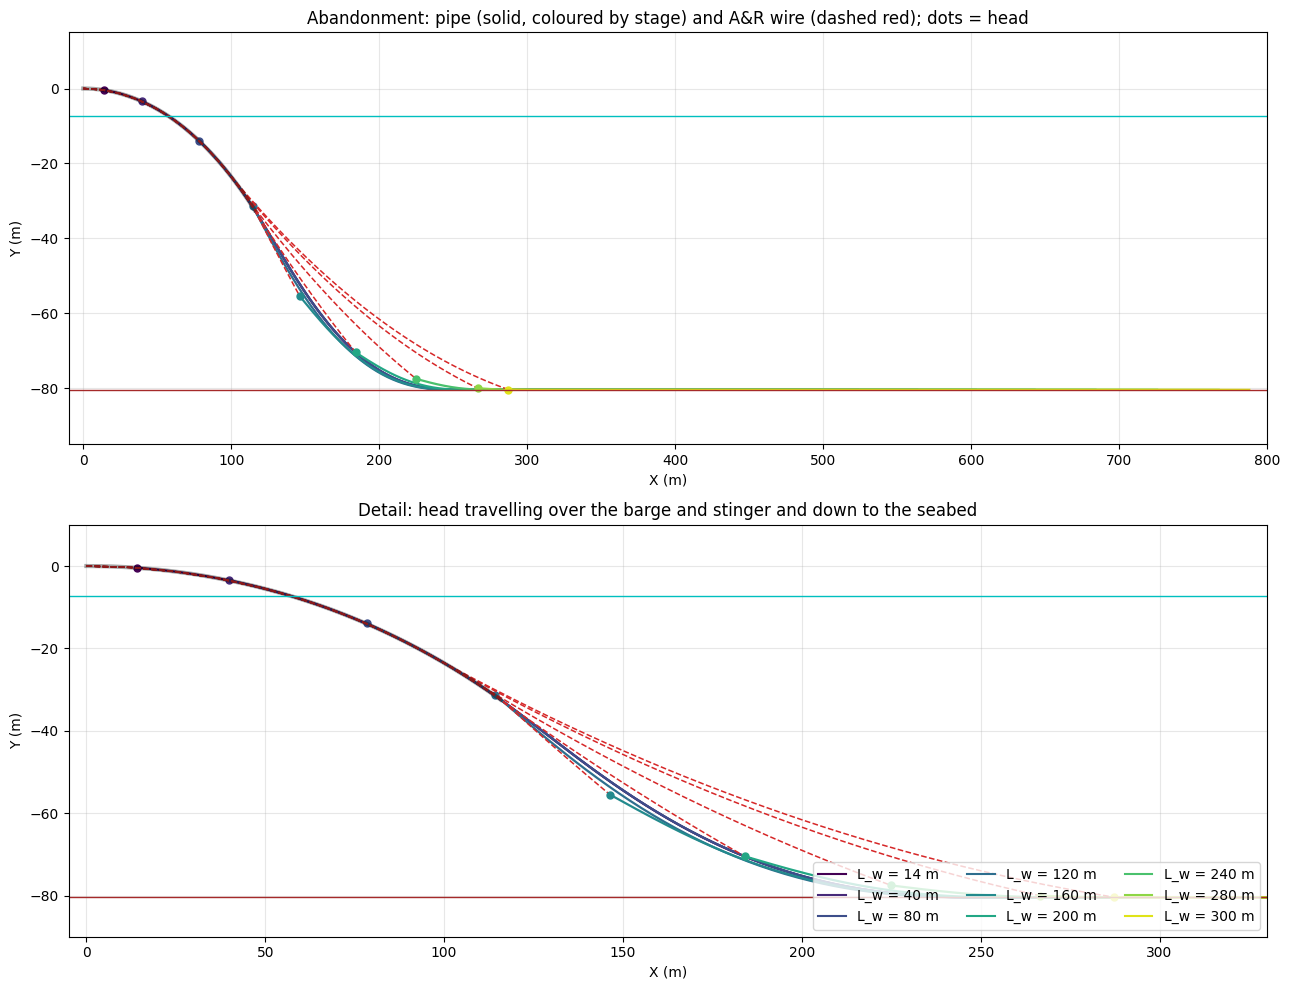

In [9]:
cm = plt.cm.viridis(np.linspace(0, 0.95, len(stages_Lw)))
def profile(ax, D, line, keys, cols, xlim=None, ylim=None, lw=1.6):
    for L, c in zip(keys, cols):
        qq = D[L]['q']; w = centreline(line, qq, line.wire_elems); p = centreline(line, qq, line.pipe_elems)
        ax.plot(p[:, 0], p[:, 1], '-', color=c, lw=lw); ax.plot(w[:, 0], w[:, 1], '--', color='tab:red', lw=1.1)
        ax.plot(*D[L]['head'], 'o', color=c, ms=5)
    ax.plot(P[:, 0], P[:, 1], 'k-', lw=3, alpha=.35); ax.axhline(line.y_water, color='c', lw=1); ax.axhline(line.y_bed, color='brown', lw=1)
    if xlim: ax.set_xlim(*xlim)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.grid(alpha=.3)
fig, ax = plt.subplots(2, 1, figsize=(13, 10))
profile(ax[0], ABAN, ar, stages_Lw, cm, xlim=(-10, 800), ylim=(-95, 15)); ax[0].set_title('Abandonment: pipe (solid, coloured by stage) and A&R wire (dashed red); dots = head')
profile(ax[1], ABAN, ar, stages_Lw, cm, xlim=(-5, 330), ylim=(-90, 10)); ax[1].set_title('Detail: head travelling over the barge and stinger and down to the seabed')
for L, c in zip(stages_Lw, cm): ax[1].plot([], [], '-', color=c, label=f'L_w = {L} m')
ax[1].legend(ncol=3, loc='lower right'); plt.tight_layout(); plt.show()

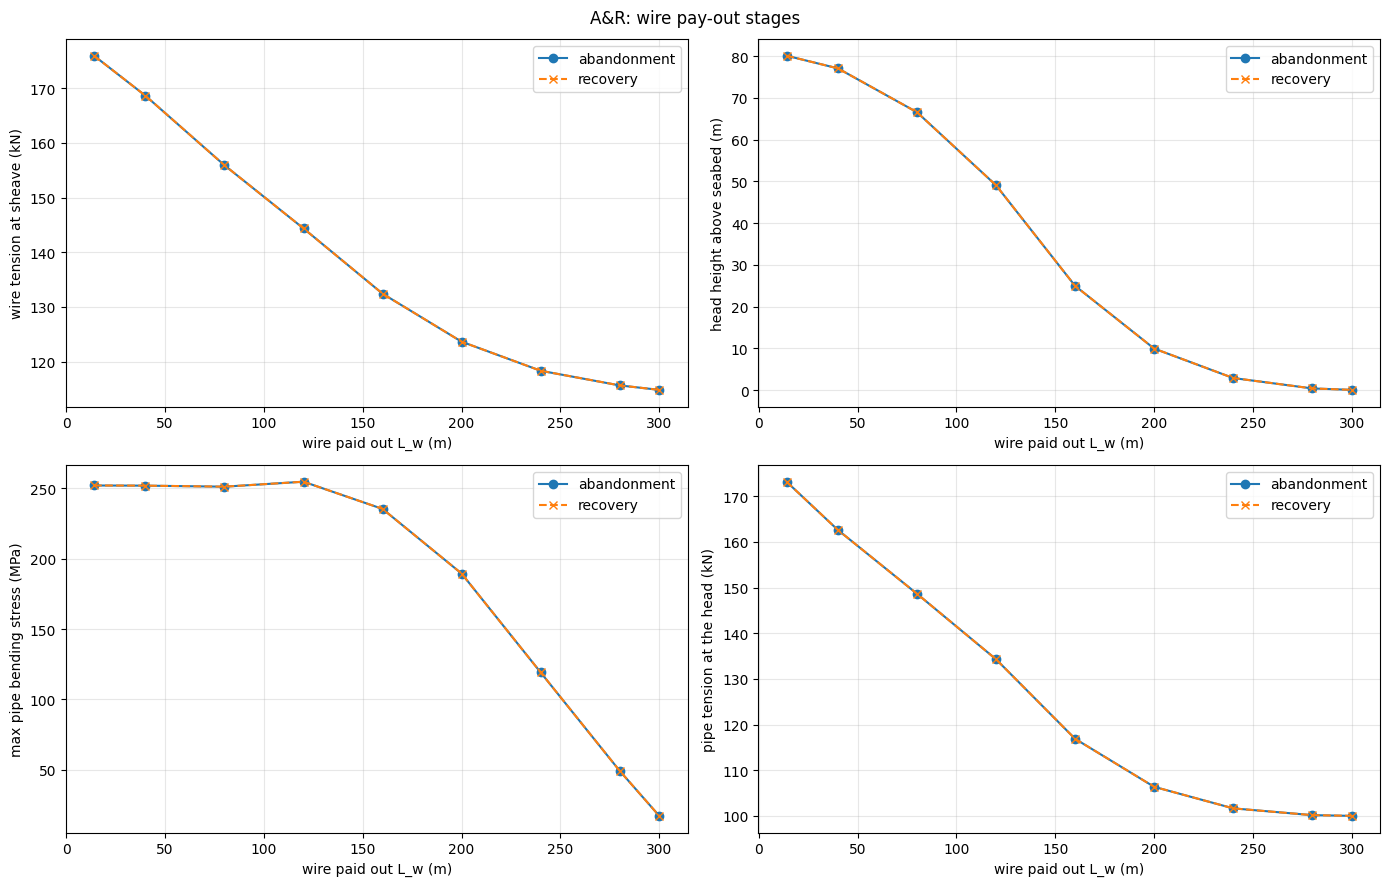

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9)); Ls = np.array(stages_Lw, float)
for D, nm, st in ((ABAN, 'abandonment', 'o-'), (REC, 'recovery', 'x--')):
    ax[0, 0].plot(Ls, [D[L]['T'][0]/1e3 for L in stages_Lw], st, label=nm)
    ax[0, 1].plot(Ls, [D[L]['clear'] for L in stages_Lw], st, label=nm)
    ax[1, 0].plot(Ls, [D[L]['sig'] for L in stages_Lw], st, label=nm)
    ax[1, 1].plot(Ls, [D[L]['T'][ar.pipe_elems[0]]/1e3 for L in stages_Lw], st, label=nm)
ax[0, 0].set_ylabel('wire tension at sheave (kN)'); ax[0, 1].set_ylabel('head height above seabed (m)'); ax[1, 0].set_ylabel('max pipe bending stress (MPa)'); ax[1, 1].set_ylabel('pipe tension at the head (kN)')
for a in ax.ravel(): a.set_xlabel('wire paid out L_w (m)'); a.grid(alpha=.3); a.legend()
plt.suptitle('A&R: wire pay-out stages'); plt.tight_layout(); plt.show()

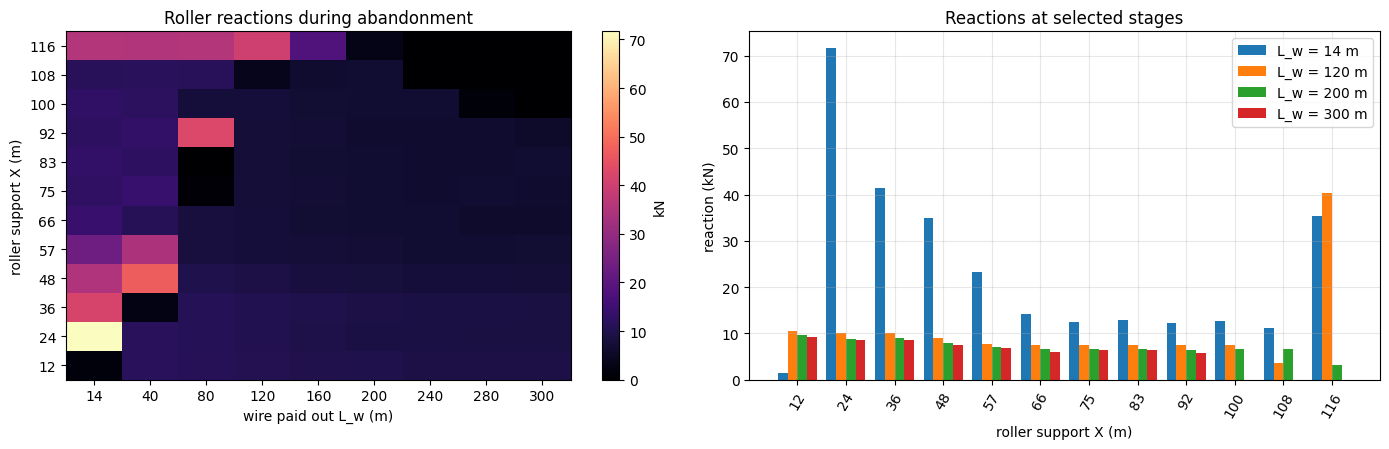

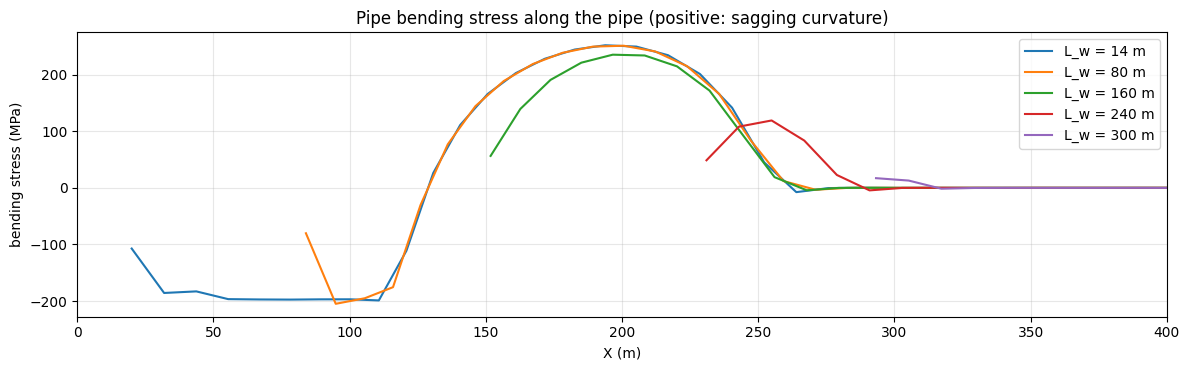

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6)); sup_x = np.array([s.P[0] for s in ar.supports])
im = ax[0].imshow(np.array([ABAN[L]['rr']/1e3 for L in stages_Lw]).T, aspect='auto', origin='lower', cmap='magma'); plt.colorbar(im, ax=ax[0], label='kN')
ax[0].set_xticks(range(len(stages_Lw))); ax[0].set_xticklabels(stages_Lw); ax[0].set_yticks(range(len(sup_x))); ax[0].set_yticklabels([f'{x:.0f}' for x in sup_x])
ax[0].set_xlabel('wire paid out L_w (m)'); ax[0].set_ylabel('roller support X (m)'); ax[0].set_title('Roller reactions during abandonment')
for L in (14, 120, 200, 300): ax[1].bar(np.arange(len(sup_x))+0.2*[14, 120, 200, 300].index(L), ABAN[L]['rr']/1e3, width=0.2, label=f'L_w = {L} m')
ax[1].set_xticks(np.arange(len(sup_x))+0.3); ax[1].set_xticklabels([f'{x:.0f}' for x in sup_x], rotation=60); ax[1].set_xlabel('roller support X (m)'); ax[1].set_ylabel('reaction (kN)'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title('Reactions at selected stages'); plt.tight_layout(); plt.show()
sel = [14, 80, 160, 240, 300]; fig, ax = plt.subplots(figsize=(12, 3.8))
for L in sel:
    qq = ABAN[L]['q']; xm = [0.5*(qq[ar.dm[ar.elems[e][0], 0]]+qq[ar.dm[ar.elems[e][1], 0]]) for e in ar.pipe_elems]
    ax.plot(xm, stress_pipe(ar, qq, ar.pipe_elems)/1e6, label=f'L_w = {L} m')
ax.set_xlim(0, 400); ax.set_xlabel('X (m)'); ax.set_ylabel('bending stress (MPa)'); ax.set_title('Pipe bending stress along the pipe (positive: sagging curvature)'); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## Part B — Pipelay initiation

Line: tensioner on the vessel (fixed at the start of the barge) – **pipe** – pull head – **steel wire** – seabed anchor. The lay tension at the tensioner is held at 40 kips; the length of pipe paid out is whatever makes that tension (extra Newton unknown). The vessel moves away from the anchor: the head, which starts high above the seabed with the pipe hanging steeply, descends along the pipe catenary until it lands on the seabed.

The final (landed) state is built first by paying out pipe with displacement control until the tension reaches the lay tension; the stages are then obtained by moving the anchor towards the vessel with the lay tension held, and are listed in lowering order (vessel moving away from the anchor).

In [12]:
ini = build_init(pipe, wire)
q = ini.q0(); ini.lam = 0.99; q, ok, _ = ini.solve(q, maxit=60)
q = march(ini, q, set_pipe_length, 0.99, 1.02, 0.002); ini.lam = 1.02       # displacement-controlled pay-out
ini.tension_control = (0, ini.T_t)
for _ in range(6):                                                        # restart Newton from the best state until converged
    q, ok, nit = ini.solve(q, maxit=60)
    if ok: break      # now hold the 40 kip lay tension, pay-out lambda is solved
print(f"landed state at the lay tension: converged {ok}; pay-out factor lambda = {ini.lam:.4f}; tensioner tension {ini.tensions(q)[0]/1e3:.1f} kN")
def snap_i(line, q):
    T = line.tensions(q); hx, hy = q[line.dm[line.head, :2]]; xA = q[line.dm[line.anchor, 0]]
    return dict(q=q.copy(), head=(hx, hy), clear=hy-line.y_bed, T=T, sig=np.abs(stress_pipe(line, q, line.pipe_elems)).max()/1e6, rr=roller_reactions(line, q), lam=line.lam, xA=xA,
                paid=sum(line.L0[e] for e in line.pipe_elems)*line.lam, res=np.linalg.norm(line.residual(q)[line.free]))
stages_xA = [380, 290, 270, 250, 230, 210, 190, 170]            # anchor X (m): landed first, then the vessel closer to the anchor
INI = {}; t0 = time.time(); xA = q[ini.dm[ini.anchor, 0]]
for tgt in stages_xA:
    if tgt != xA: q = march(ini, q, set_anchor_x, xA, tgt, 2.5); xA = tgt
    else: q, ok, _ = ini.solve(q)
    INI[tgt] = snap_i(ini, q)
print(f"initiation: {len(stages_xA)} stages in {time.time()-t0:.0f} s; worst residual {max(v['res'] for v in INI.values()):.2e} N")

landed state at the lay tension: converged True; pay-out factor lambda = 1.0064; tensioner tension 177.9 kN
initiation: 8 stages in 249 s; worst residual 6.88e-01 N


In [13]:
stages_i = stages_xA[::-1]            # lowering order: vessel moves away from the anchor
x_tip = arc(S_TIP)[0, 0]
print('INITIATION (lowering: vessel moving away from the anchor)')
print(f"{'stage':>5s}{'anchor X':>10s}{'dist. tip-anchor':>18s}{'head X':>9s}{'head Y':>9s}{'clear':>8s}{'pipe paid':>11s}{'T tensioner':>13s}{'T wire@head':>13s}{'max bend.':>11s}{'max roller':>11s}")
print(f"{'':>5s}{'(m)':>10s}{'(m)':>18s}{'(m)':>9s}{'(m)':>9s}{'(m)':>8s}{'(m)':>11s}{'(kN)':>13s}{'(kN)':>13s}{'(MPa)':>11s}{'(kN)':>11s}")
for k, xa in enumerate(stages_i):
    d = INI[xa]; print(f"{k:5d}{xa:10.0f}{xa-x_tip:18.0f}{d['head'][0]:9.1f}{d['head'][1]:9.1f}{d['clear']:8.1f}{d['paid']:11.1f}{d['T'][0]/1e3:13.1f}{d['T'][ini.wire_elems[0]]/1e3:13.1f}{d['sig']:11.1f}{d['rr'].max()/1e3:11.1f}")

INITIATION (lowering: vessel moving away from the anchor)
stage  anchor X  dist. tip-anchor   head X   head Y   clear  pipe paid  T tensioner  T wire@head  max bend. max roller
            (m)               (m)      (m)      (m)     (m)        (m)         (kN)         (kN)      (MPa)       (kN)
    0       170                54    130.1    -42.6    37.8      139.3        177.9        129.2      336.9       84.0
    1       190                74    143.2    -51.6    28.8      155.2        177.9        120.2      243.2       84.1
    2       210                94    159.0    -59.9    20.6      173.0        177.9        115.0      229.0       83.9
    3       230               114    176.6    -67.1    13.3      191.9        177.9        110.8      212.2       83.9
    4       250               134    195.4    -73.7     6.8      211.7        177.9        106.8      207.3       84.0
    5       270               154    215.0    -79.7     0.8      232.4        177.9        103.3      213.7  

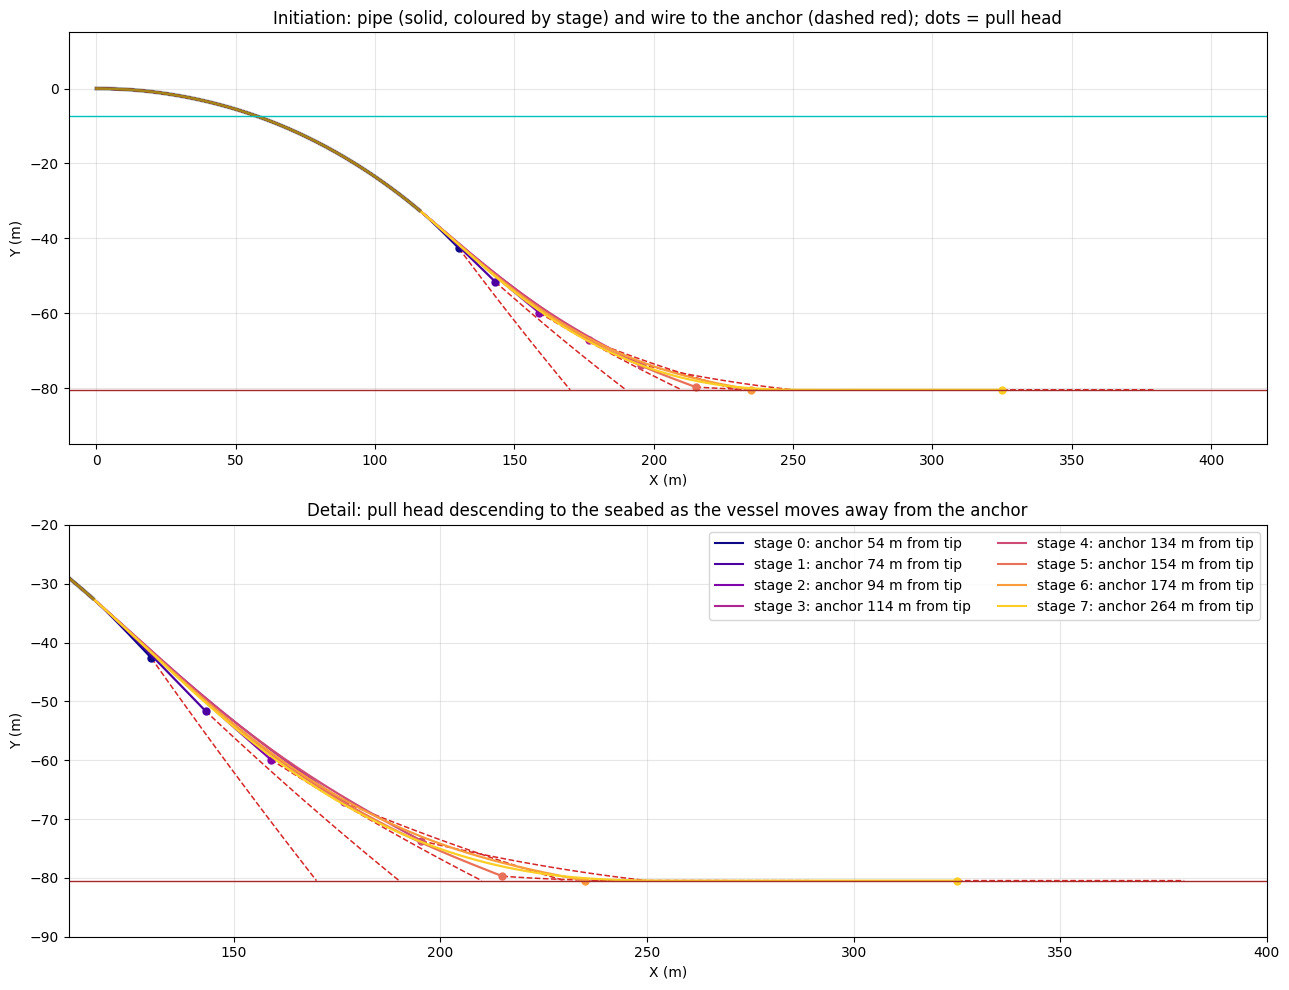

In [14]:
cmi = plt.cm.plasma(np.linspace(0, 0.9, len(stages_i)))
fig, ax = plt.subplots(2, 1, figsize=(13, 10))
profile(ax[0], INI, ini, stages_i, cmi, xlim=(-10, 420), ylim=(-95, 15)); ax[0].set_title('Initiation: pipe (solid, coloured by stage) and wire to the anchor (dashed red); dots = pull head')
profile(ax[1], INI, ini, stages_i, cmi, xlim=(110, 400), ylim=(-90, -20)); ax[1].set_title('Detail: pull head descending to the seabed as the vessel moves away from the anchor')
for k, (xa, c) in enumerate(zip(stages_i, cmi)): ax[1].plot([], [], '-', color=c, label=f'stage {k}: anchor {xa-x_tip:.0f} m from tip')
ax[1].legend(ncol=2, loc='upper right'); plt.tight_layout(); plt.show()

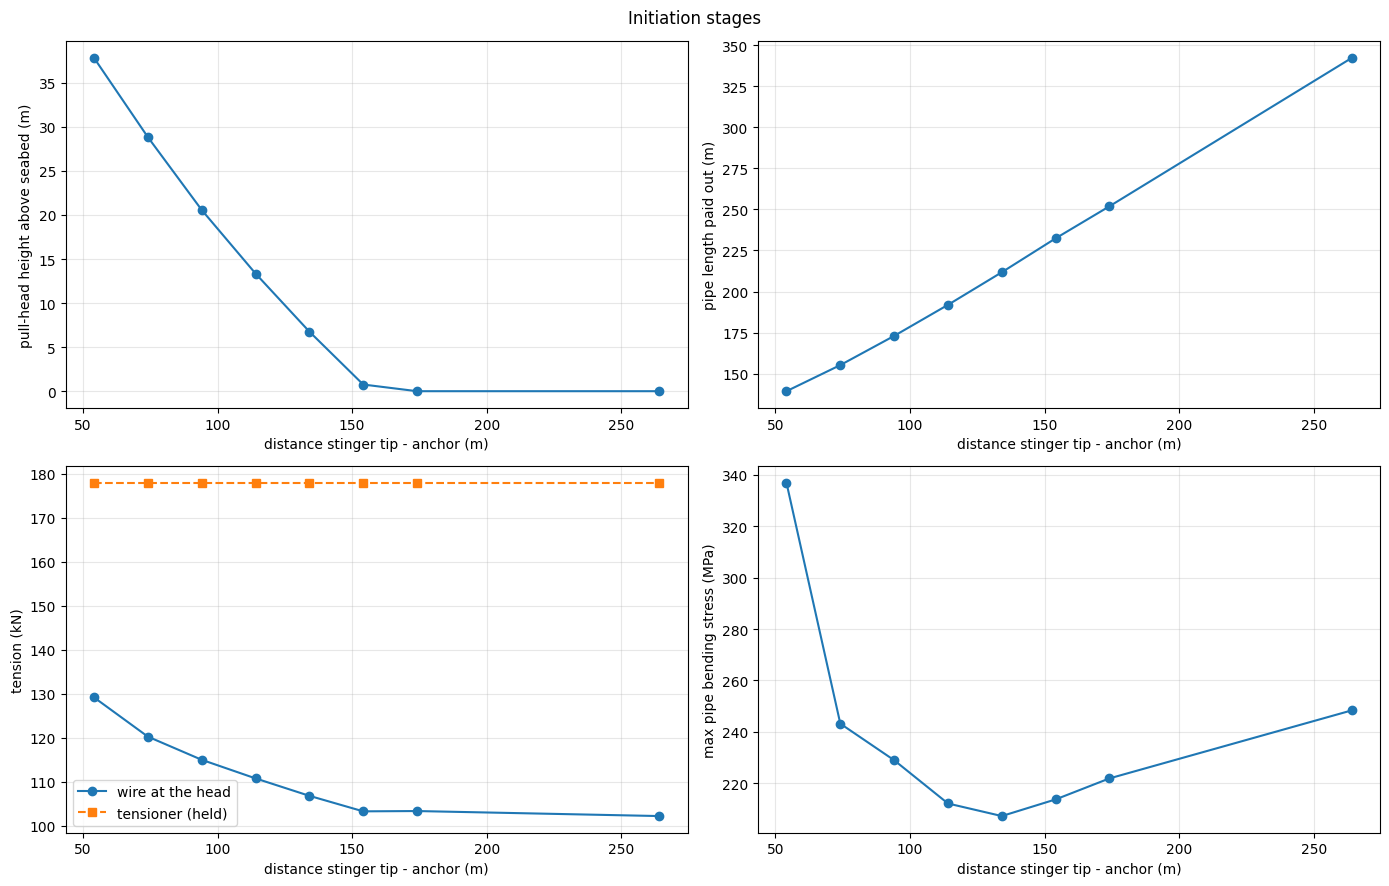

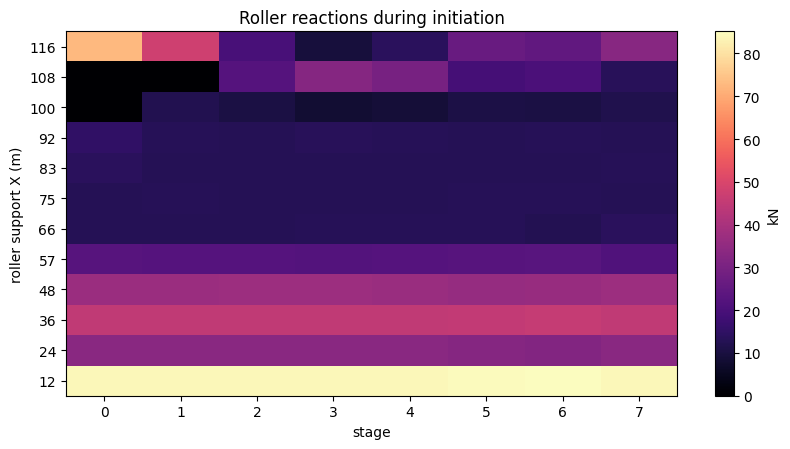

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9)); dist = np.array([xa-x_tip for xa in stages_i])
ax[0, 0].plot(dist, [INI[x]['clear'] for x in stages_i], 'o-'); ax[0, 0].set_ylabel('pull-head height above seabed (m)')
ax[0, 1].plot(dist, [INI[x]['paid'] for x in stages_i], 'o-'); ax[0, 1].set_ylabel('pipe length paid out (m)')
ax[1, 0].plot(dist, [INI[x]['T'][ini.wire_elems[0]]/1e3 for x in stages_i], 'o-', label='wire at the head'); ax[1, 0].plot(dist, [INI[x]['T'][0]/1e3 for x in stages_i], 's--', label='tensioner (held)')
ax[1, 0].set_ylabel('tension (kN)'); ax[1, 0].legend()
ax[1, 1].plot(dist, [INI[x]['sig'] for x in stages_i], 'o-'); ax[1, 1].set_ylabel('max pipe bending stress (MPa)')
for a in ax.ravel(): a.set_xlabel('distance stinger tip - anchor (m)'); a.grid(alpha=.3)
plt.suptitle('Initiation stages'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8.5, 4.6)); sup_x = np.array([s.P[0] for s in ini.supports])
im = ax.imshow(np.array([INI[x]['rr']/1e3 for x in stages_i]).T, aspect='auto', origin='lower', cmap='magma'); plt.colorbar(im, ax=ax, label='kN')
ax.set_xticks(range(len(stages_i))); ax.set_xticklabels(range(len(stages_i))); ax.set_xlabel('stage'); ax.set_yticks(range(len(sup_x))); ax.set_yticklabels([f'{x:.0f}' for x in sup_x]); ax.set_ylabel('roller support X (m)')
ax.set_title('Roller reactions during initiation'); plt.tight_layout(); plt.show()

## Notes
* **Reading the results.** The A&R wire carries essentially the pipe tension at the head (stage 0: ≈ 176 kN), which falls as the head goes down because more of the line is carried by the water and the stinger; the pipe tension at the head is slightly lower than the wire tension by the head weight and the wire weight. In the initiation the lay tension is fixed by construction, so the quantities to read are the pay-out, the head height and the wire tension.
* **Seabed lay tension.** In abandonment the seabed end is held by a horizontal force, so the far end of the pipe moves forward by about the wire pay-out (equivalent to the vessel moving ahead relative to a fixed pipeline). Change `H_far` in `build_ar` to study other lay tensions.
* **Where to extend:** friction on rollers and seabed (path-dependent recovery), a flooded or water-filled pipe (needs a higher seabed lay tension; with 100 kN the flooded line overstresses on the stinger), a flexible stinger (more elements with the same line model), current/wave drag and vessel motion (the dynamic machinery of the earlier notebook applies to this chain), a roller-wire contact offset for the smaller wire radius, and pipe-to-wire connection stiffness at the head.
* **Not validated** against measured or published data for these operations; the thesis covers the pipelay element and static/dynamic solution method, not these operations.